In [1]:
# Machine Learning Midterm – Breast Cancer Wisconsin
#Muhammed Efe Öneş – 23040202015

In [6]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [7]:
#PART 1 loading Data set
#1.1 loading data set from sicit-learn
from sklearn.datasets import load_breast_cancer
data= load_breast_cancer()
print(type(data))
print(data.keys()) # different parts of the data set

<class 'sklearn.utils._bunch.Bunch'>
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [8]:
#1.2 Creating the data frames
X = pd.DataFrame(data.data, columns=data.feature_names) # to give names for the columns in data (easy to read)
y = pd.Series(data.target, name="target") #like in x but only for target column
print("X shape:", X.shape)
print("y shape:", y.shape) 
X.head() #For first five 
y.head() 

X shape: (569, 30)
y shape: (569,)


0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [9]:
print("Feature names:", list(X.columns)) #names of the colum in data set 
print("Target labels:", np.unique(y)) #shows how different answer in the colummn 
print("Target names :", list(data.target_names))

Feature names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Target labels: [0 1]
Target names : [np.str_('malignant'), np.str_('benign')]


In [11]:
counts = y.value_counts().sort_index() #it coun how many persons for every class (without sort_index values will be mixed)
class_overview = pd.DataFrame({
    "label": counts.index, #[0,1]
    "name": data.target_names, #[malignant [0 cancer] (positive), benign[1 not cancer] (names of 0,1)]
    "n_samples": counts.values, #[values of how many 0&1 in counts]
})
class_overview["percent"] = (100 * class_overview["n_samples"] / len(y)).round(2) #percenteces of sick and healty people in data set 
class_overview

,label,name,n_samples,percent
0,0,malignant,212,37.26
1,1,benign,357,62.74


In [12]:
# 2. Dataset Quality Checks
#2.1 Missing values and duplicates

In [14]:
missing = X.isna().sum() #to find missing values and sum them up 
display(missing.to_frame("missing_count"))  
print("Total missing values:", missing.sum())

n_duplicates = X.duplicated().sum() #to find işs there any dublicatre rows for protecting ml from leacge
print("Duplicate rows:", n_duplicates)

if missing.sum() == 0:
    print("No missing values are present.")
if n_duplicates == 0:
    print("No duplicate rows are present.")

,missing_count
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


Total missing values: 0
Duplicate rows: 0
No missing values are present.
No duplicate rows are present.


In [15]:
# 2.2 Potential outliers
outlier_rows = [] 
for col in X.columns:
    q1 = X[col].quantile(0.25)
    q3 = X[col].quantile(0.75)
    iqr = q3 - q1 
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_iqr = ((X[col] < lower) | (X[col] > upper)).sum() #is the valur smaller than lower or bigger than upper? if yes, sum it up

    z = (X[col] - X[col].mean()) / X[col].std() #z score 
    n_z = (z.abs() > 3).sum()

    outlier_rows.append({
        "feature": col,
        "n_iqr_outliers": n_iqr,
        "pct_iqr": round(100 * n_iqr / len(X), 2),
        "n_abs_z_gt_3": n_z,
    })

outliers = pd.DataFrame(outlier_rows).sort_values("n_iqr_outliers", ascending=False) #puts bigest value to the top
print("Features with at least one IQR outlier:", (outliers["n_iqr_outliers"] > 0).sum(), "of", X.shape[1])
outliers
#29 of 30 features have some outliers. Most of them are in "error" and "area" features. we find them to make our model more acurate

Features with at least one IQR outlier: 29 of 30


,feature,n_iqr_outliers,pct_iqr,n_abs_z_gt_3
13,area error,65,11.42,6
10,radius error,38,6.68,7
12,perimeter error,38,6.68,8
23,worst area,35,6.15,10
14,smoothness error,30,5.27,7
19,fractal dimension error,28,4.92,10
15,compactness error,28,4.92,12
18,symmetry error,27,4.75,11
3,mean area,25,4.39,8
29,worst fractal dimension,24,4.22,9


In [16]:
# 2.3 Data types
display(X.dtypes.to_frame("dtype")) #it shows data type of all columns

n_numeric = X.select_dtypes(include="number").shape[1] # gives the nnumber of numeric columns in the data set
n_categorical = X.shape[1] - n_numeric
print("Numerical features  :", n_numeric)
print("Categorical features:", n_categorical)

zero_counts = (X == 0).sum() #how many zeros in each column
print("\nFeatures that contain exact zeros:")
print(zero_counts[zero_counts > 0])
#There are no missing values and no duplicate rows, so no imputation is needed. All 30 features are numerical. Some features have outliers and some have exact zeros, but these look like real values, so I did not change the data.

,dtype
mean radius,float64
mean texture,float64
mean perimeter,float64
mean area,float64
mean smoothness,float64
mean compactness,float64
mean concavity,float64
mean concave points,float64
mean symmetry,float64
mean fractal dimension,float64


Numerical features  : 30
Categorical features: 0

Features that contain exact zeros:
mean concavity          13
mean concave points     13
concavity error         13
concave points error    13
worst concavity         13
worst concave points    13
dtype: int64


In [17]:
# 3. Exploratory DAta analysis (EDA)
# 3.1 Descriptive statistics
desc = pd.DataFrame({
    "mean": X.mean(),
    "median": X.median(),
    "min": X.min(),
    "max": X.max(),
    "std": X.std(),
    "Q1": X.quantile(0.25),
    "Q3": X.quantile(0.75),
}).round(4)
desc
#if mean and median are close to each other, the distribution is symmetric. 

,mean,median,min,max,std,Q1,Q3
mean radius,14.1273,13.3700,6.9810,28.1100,3.5240,11.7000,15.7800
mean texture,19.2896,18.8400,9.7100,39.2800,4.3010,16.1700,21.8000
mean perimeter,91.9690,86.2400,43.7900,188.5000,24.2990,75.1700,104.1000
mean area,654.8891,551.1000,143.5000,2501.0000,351.9141,420.3000,782.7000
mean smoothness,0.0964,0.0959,0.0526,0.1634,0.0141,0.0864,0.1053
mean compactness,0.1043,0.0926,0.0194,0.3454,0.0528,0.0649,0.1304
mean concavity,0.0888,0.0615,0.0000,0.4268,0.0797,0.0296,0.1307
mean concave points,0.0489,0.0335,0.0000,0.2012,0.0388,0.0203,0.0740
mean symmetry,0.1812,0.1792,0.1060,0.3040,0.0274,0.1619,0.1957
mean fractal dimension,0.0628,0.0615,0.0500,0.0974,0.0071,0.0577,0.0661


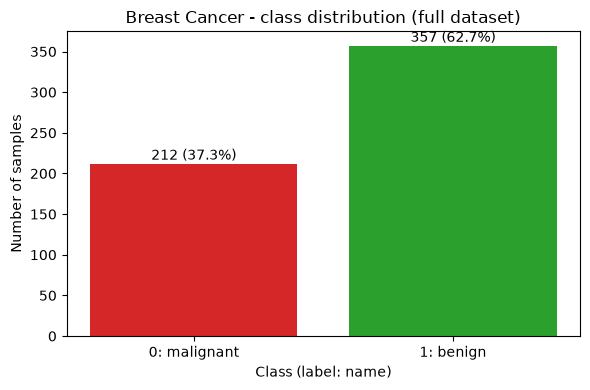

In [18]:
# 3.2 Class distribution and correlations
import os
os.makedirs("figures", exist_ok=True)

counts = y.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["0: malignant", "1: benign"], counts.values, color=["tab:red", "tab:green"])
for i, c in enumerate(counts.values):
    ax.text(i, c + 5, f"{c} ({100 * c / len(y):.1f}%)", ha="center")
ax.set_xlabel("Class (label: name)")
ax.set_ylabel("Number of samples")
ax.set_title("Breast Cancer - class distribution (full dataset)")
plt.tight_layout()
plt.savefig("figures/bc_class_distribution.png", dpi=150)
plt.show()
#this part basicly plots the graph of how many healty and sick percenteces

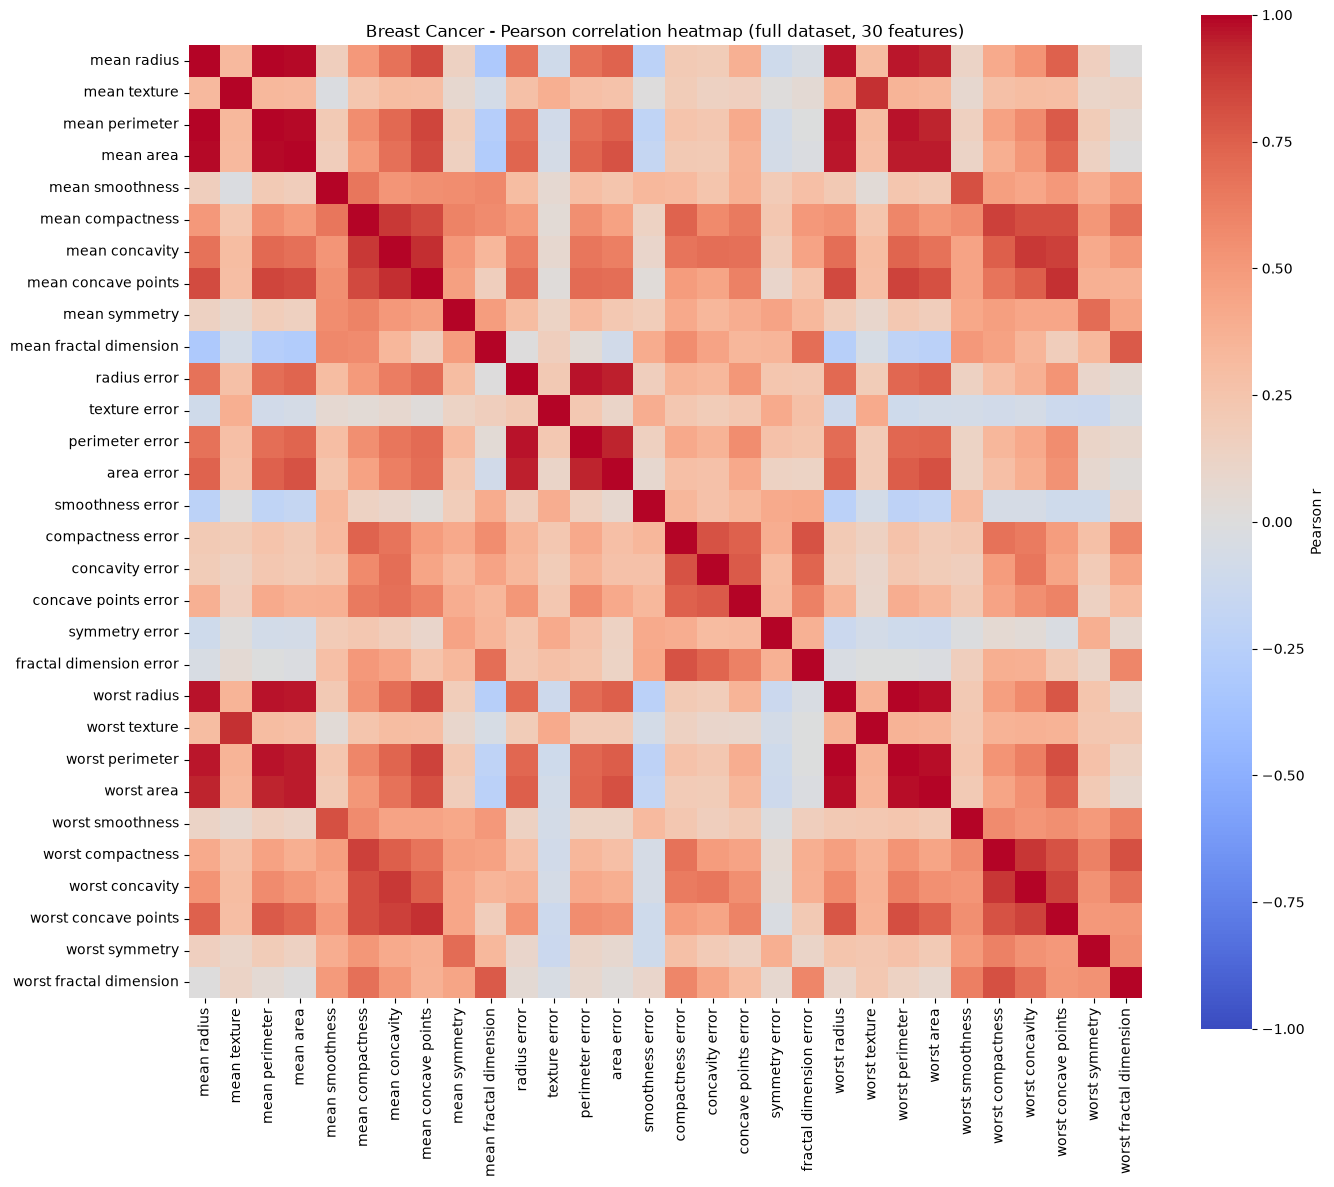

In [ ]:
corr = X.corr(method="pearson") #30x30 bi tablo üretir

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, ax=ax, #heat map (coolwarm red positive blue negative orantı)(v min and max for vcolor bar to not make more complicated)
            cbar_kws={"label": "Pearson r"})
ax.set_title("Breast Cancer - Pearson correlation heatmap (full dataset, 30 features)")
plt.tight_layout()
plt.savefig("figures/bc_correlation_heatmap.png", dpi=150)
plt.show()

In [20]:
pairs = []
cols = corr.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):#j is starts from i+1 to avoid corners because every feature is  perfect korelasyon
        pairs.append((cols[i], cols[j], corr.iloc[i, j]))

pairs = pd.DataFrame(pairs, columns=["feature_1", "feature_2", "pearson_r"])
pairs["abs_r"] = pairs["pearson_r"].abs()
top3 = pairs.sort_values("abs_r", ascending=False).head(3)
print("Number of unique pairs:", len(pairs))
top3

Number of unique pairs: 435


,feature_1,feature_2,pearson_r,abs_r
1,mean radius,mean perimeter,0.997855,0.997855
391,worst radius,worst perimeter,0.993708,0.993708
2,mean radius,mean area,0.987357,0.987357


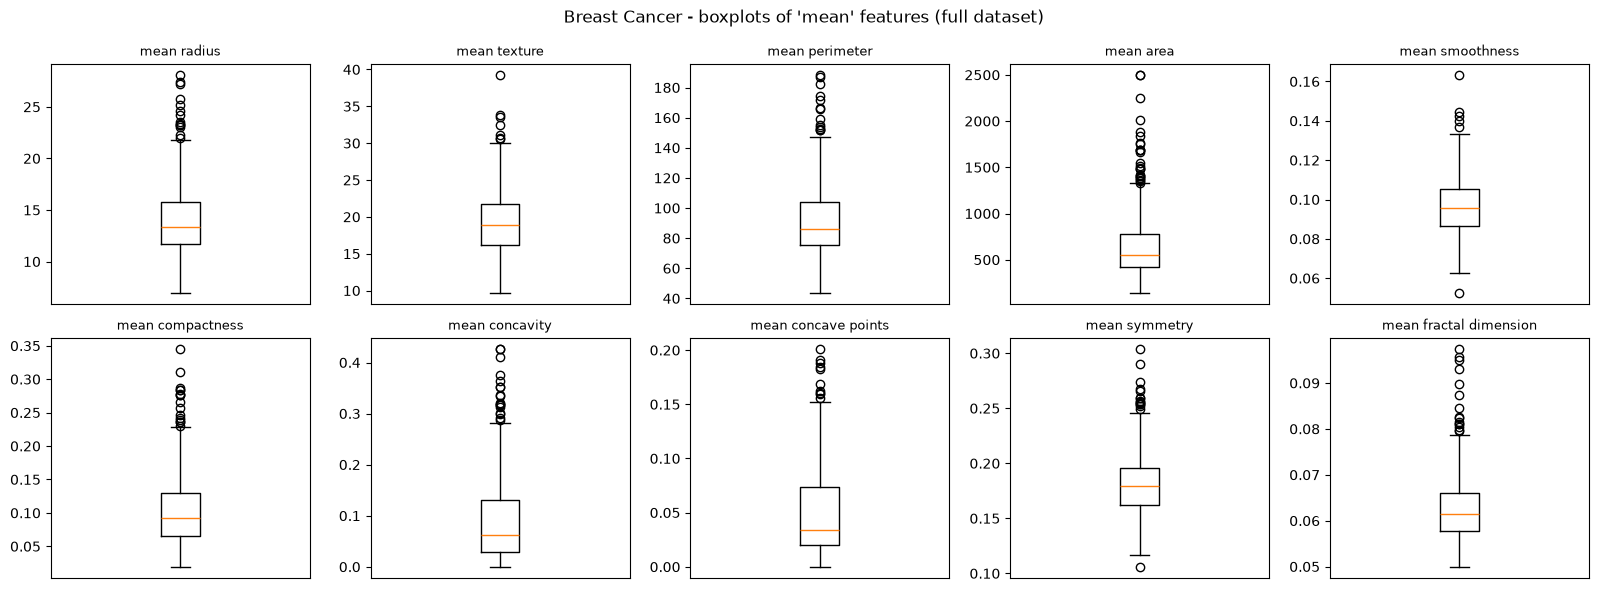

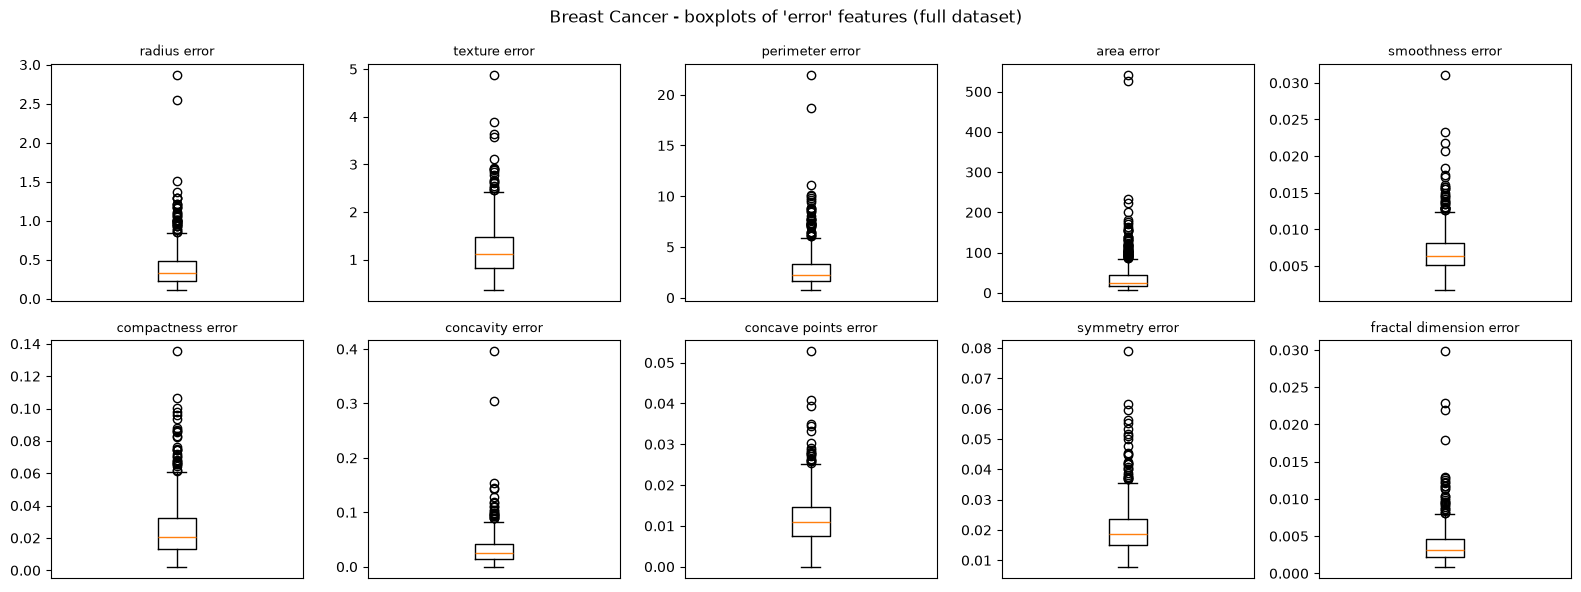

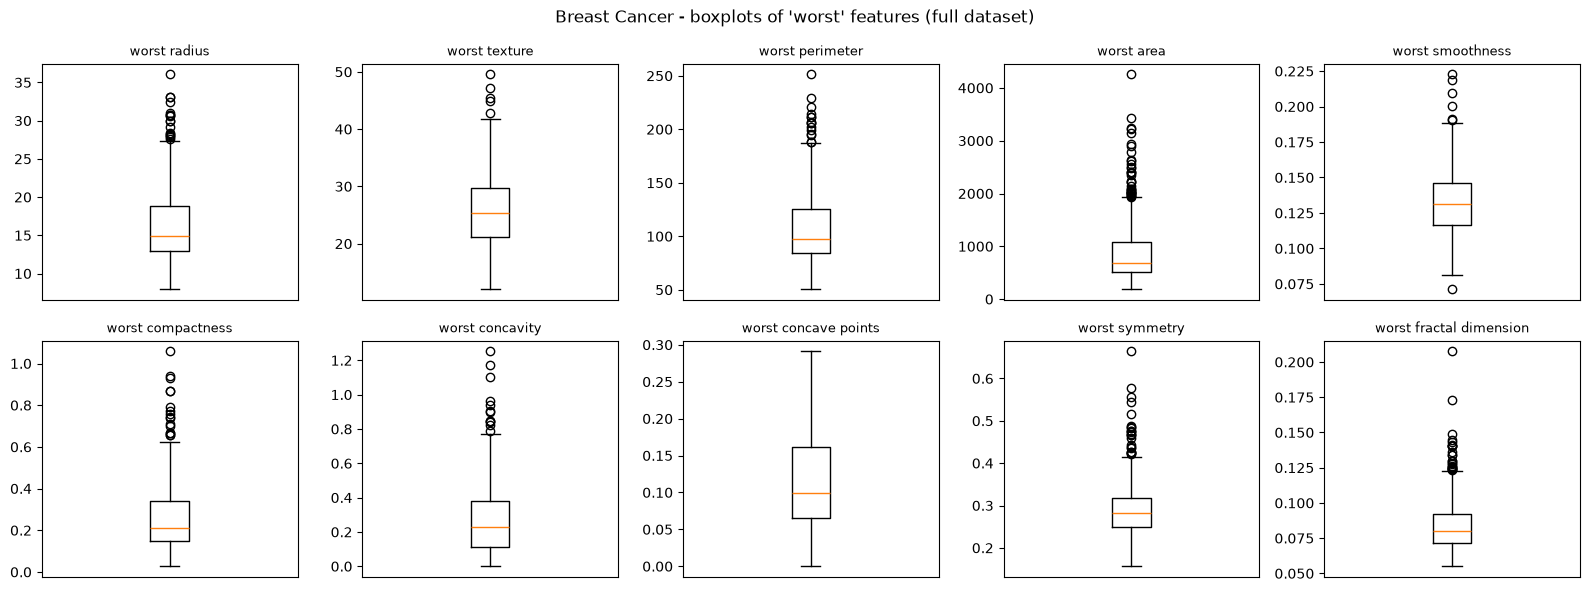

In [22]:
# 3.3 Boxplots
def plot_boxplots(features, title, filename): #[it's like a cast if you put wanted values it will give you same shape but with different materials]
    fig, axes = plt.subplots(2, 5, figsize=(16, 6))
    for ax, col in zip(axes.ravel(), features):
        ax.boxplot(X[col])
        ax.set_title(col, fontsize=9)
        ax.set_xticks([])
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

mean_cols  = [c for c in X.columns if c.startswith("mean")]
error_cols = [c for c in X.columns if c.endswith("error")]
worst_cols = [c for c in X.columns if c.startswith("worst")]

plot_boxplots(mean_cols,  "Breast Cancer - boxplots of 'mean' features (full dataset)",  "figures/bc_boxplots_mean.png")
plot_boxplots(error_cols, "Breast Cancer - boxplots of 'error' features (full dataset)", "figures/bc_boxplots_error.png")
plot_boxplots(worst_cols, "Breast Cancer - boxplots of 'worst' features (full dataset)", "figures/bc_boxplots_worst.png")

In [ ]:
# 4. Splitting the Dataset
# 4.1 Fix the test set and repeat the training/validation split
from sklearn.model_selection import train_test_split

SEEDS = [42, 52, 62]

# 20% test set, created ONCE
X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

# for each seed: split the remaining 80% into train (70%) and validation (10%)
splits = {}
for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(
        X_rest, y_rest, test_size=0.125, stratify=y_rest, random_state=seed)
    splits[seed] = {"X_train": X_train, "X_val": X_val, "y_train": y_train, "y_val": y_val}

In [26]:
# 4.2 Verify the split
rows = []
for seed in SEEDS:
    for name, ys in [("train", splits[seed]["y_train"]),
                     ("validation", splits[seed]["y_val"]),
                     ("test", y_test)]:
        rows.append({"seed": seed, "subset": name, "n": len(ys),
                     "percent": round(100 * len(ys) / len(y), 2),
                     "malignant (0)": (ys == 0).sum(),
                     "benign (1)": (ys == 1).sum()})

split_summary = pd.DataFrame(rows)
split_summary
# this table shows how many patients go to train, validation and test for every seed, like a little report card for the split

,seed,subset,n,percent,malignant (0),benign (1)
0,42,train,398,69.95,149,249
1,42,validation,57,10.02,21,36
2,42,test,114,20.04,42,72
3,52,train,398,69.95,149,249
4,52,validation,57,10.02,21,36
5,52,test,114,20.04,42,72
6,62,train,398,69.95,149,249
7,62,validation,57,10.02,21,36
8,62,test,114,20.04,42,72


In [27]:
for seed in SEEDS:
    tr = splits[seed]["X_train"].index
    va = splits[seed]["X_val"].index
    te = X_test.index
    print(f"Seed {seed}: overlaps = {len(tr.intersection(va))}, {len(tr.intersection(te))}, {len(va.intersection(te))} | "
          f"total = {len(tr) + len(va) + len(te)} | first val rows = {sorted(va)[:5]}")

print("Test rows (same for all seeds), first 10:", sorted(X_test.index)[:10])
# here we check nobody is in two groups at same time, total is still 569 and test group is same in every seed


Seed 42: overlaps = 0, 0, 0 | total = 569 | first val rows = [7, 13, 15, 27, 38]
Seed 52: overlaps = 0, 0, 0 | total = 569 | first val rows = [13, 82, 87, 90, 98]
Seed 62: overlaps = 0, 0, 0 | total = 569 | first val rows = [26, 31, 33, 34, 36]
Test rows (same for all seeds), first 10: [1, 14, 20, 23, 24, 41, 51, 64, 70, 73]


In [ ]:
# 5. Data Preprocessing and Scaling
# 5.1 Missing values
#There are no missing values (from Section 2.1), so no imputation step is needed.
# 5.2 Selected scaler
#use Standardscaler for all seeds and for both datasets.
# 5.3 Fit and apply the scaler

In [32]:
# every seed gets its own new ruler, made only from its own train data
from sklearn.preprocessing import StandardScaler

scalers = {} #box for keeping the ruler of every seed
scaled = {} # box for keeping scaled train and val of every seed
for seed in SEEDS: # do same thing 3 times: seed 42, 52, 62
    scaler = StandardScaler().set_output(transform="pandas")
    scaler.fit(splits[seed]["X_train"])# ruler learns mean and std ONLY from train, never from val or test (no leakage)
    scaled[seed] = {"X_train": scaler.transform(splits[seed]["X_train"]),
                    "X_val": scaler.transform(splits[seed]["X_val"])}

print("mean area learned by each scaler:", [round(scalers[s].mean_[3], 1) for s in SEEDS])

mean area learned by each scaler: [np.float64(653.7), np.float64(640.9), np.float64(653.3)]


In [ ]:
# test set is measured only with the seed 42 ruler
X_test_scaled = scalers[42].transform(X_test)

print("BEFORE scaling (seed 42, first 5 train rows)")
display(splits[42]["X_train"].head().round(3)) # original values, very different sizes 
print("AFTER scaling (seed 42, first 5 train rows)")
display(scaled[42]["X_train"].head().round(3))

BEFORE scaling (seed 42, first 5 train rows)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.085,0.101,0.068,0.031,0.178,0.062,...,13.46,23.07,88.13,551.3,0.105,0.216,0.190,0.076,0.268,0.078
390,10.26,12.22,65.75,321.6,0.100,0.075,0.019,0.020,0.180,0.066,...,11.38,15.65,73.23,394.5,0.134,0.165,0.086,0.067,0.294,0.077
420,11.57,19.04,74.20,409.7,0.085,0.077,0.055,0.014,0.203,0.063,...,13.07,26.98,86.43,520.5,0.125,0.194,0.256,0.067,0.304,0.083
356,13.05,18.59,85.09,512.0,0.108,0.130,0.096,0.056,0.204,0.065,...,14.19,24.85,94.22,591.2,0.134,0.266,0.257,0.126,0.311,0.083
446,17.75,28.03,117.30,981.6,0.100,0.131,0.170,0.083,0.171,0.059,...,21.53,38.54,145.40,1437.0,0.140,0.376,0.640,0.197,0.297,0.091


AFTER scaling (seed 42, first 5 train rows)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.465,0.177,-0.468,-0.519,-0.884,-0.073,-0.281,-0.467,-0.077,-0.069,...,-0.573,-0.379,-0.561,-0.578,-1.226,-0.259,-0.416,-0.585,-0.340,-0.358
390,-1.084,-1.553,-1.065,-0.944,0.251,-0.554,-0.869,-0.753,-0.010,0.375,...,-1.001,-1.547,-1.000,-0.855,0.070,-0.573,-0.893,-0.724,0.046,-0.381
420,-0.715,-0.015,-0.721,-0.694,-0.814,-0.521,-0.442,-0.889,0.806,-0.044,...,-0.654,0.237,-0.611,-0.633,-0.346,-0.396,-0.117,-0.728,0.196,-0.074
356,-0.299,-0.116,-0.278,-0.403,0.855,0.463,0.052,0.166,0.821,0.281,...,-0.423,-0.099,-0.382,-0.508,0.070,0.049,-0.111,0.155,0.315,-0.055
446,1.024,2.013,1.034,0.933,0.251,0.482,0.936,0.846,-0.317,-0.532,...,1.086,2.057,1.128,0.984,0.327,0.731,1.638,1.218,0.100,0.359


In [33]:
# 6. Preparing the Two Data Representations
# two versions of same data: unscaled (original) and scaled, same patients in both
reps = {}
for seed in SEEDS:
    reps[seed] = {"unscaled": (splits[seed]["X_train"], splits[seed]["X_val"]),
                  "scaled":   (scaled[seed]["X_train"], scaled[seed]["X_val"])}
    #main purpose is to hold both of the datas next to eachother
    

7 Training the Classification Models
7.1 Required experiments
11 settings × 2 representations × 3 seeds = 66 runs.

In [ ]:
from sklearn.tree import DecisionTreeClassifier #it's ask yes or no questions to make a decision AND DEPTS MEANİNG HOW MANY TİMES 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

CONFIGS = [("dt", 2, "d2"), ("dt", 3, "d3"), ("dt", 5, "d5"), ("dt", 10, "d10"), ("dt", None, "dNone"), #a list for differnt type of configurations for different algorithms
           ("knn", 1, "k1"), ("knn", 3, "k3"), ("knn", 5, "k5"), ("knn", 7, "k7"), ("knn", 11, "k11"),
           ("gnb", None, "default")]

def make_model(algo, param, seed): # basicly a start button for eitch configuration we will use
    if algo == "dt":
        return DecisionTreeClassifier(max_depth=param, random_state=seed)
    if algo == "knn":
        return KNeighborsClassifier(n_neighbors=param, weights="uniform", metric="euclidean")
    return GaussianNB()

In [35]:
#       7.2 Record the experiments
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score #we import our tools

def val_metrics(model, X_val, y_val):
    pred = model.predict(X_val)
    proba = model.predict_proba(X_val)
    assert list(model.classes_) == [0, 1]
    never = [c for c in [0, 1] if (pred == c).sum() == 0]
    return {
        "val_accuracy": accuracy_score(y_val, pred), #correct predictions / total predictions
        "val_macro_precision": precision_score(y_val, pred, average="macro", zero_division=0),#it calculates precision for every class
        "val_macro_recall": recall_score(y_val, pred, average="macro", zero_division=0),
        "val_macro_f1": f1_score(y_val, pred, average="macro", zero_division=0), #we selck model acarding to this value
        "val_roc_auc": roc_auc_score(y_val == 0, proba[:, 0]),
        "undefined_precision_classes": str(never) if never else "none",
    }

In [36]:
# 3 loops inside each other: 3 seeds x 2 representations x 11 settings = 66 runs
rows = []          # empty list, every run will add one row here
models_42 = {}  # keep seed 42 models for final test

for seed in SEEDS:   # loop 1 for seed 42, 52, 62
    y_train = splits[seed]["y_train"]
    y_val = splits[seed]["y_val"]
    for rep in ["unscaled", "scaled"]:   # loop 2: two versions of data
        X_train_r, X_val_r = reps[seed][rep] #it takes val and traning copules
        for algo, param, tag in CONFIGS:        # loop 3: 11 settings
            model = make_model(algo, param, seed)    # new empty model from factory
            model.fit(X_train_r, y_train)      # learn ONLY from TRAİN
            config_id = f"breast_cancer_{algo}_{rep}_{tag}" #it's to understand witch model is used for which configuration
            train_pred = model.predict(X_train_r) #how well model knows train quess from train data
            row = {"run_id": f"{config_id}_s{seed}", "config_id": config_id, "dataset": "breast_cancer", #name of run and 2 train scores 
                   "seed": seed, "algorithm": algo, "representation": rep, "parameter": tag,
                   "train_accuracy": accuracy_score(y_train, train_pred),
                   "train_macro_f1": f1_score(y_train, train_pred, average="macro")}
            row.update(val_metrics(model, X_val_r, y_val))   # add 5 validation scores
            rows.append(row)
            if seed == 42:
                models_42[config_id] = model

runs = pd.DataFrame(rows)
print("Number of runs:", len(runs), "| seed-42 models kept:", len(models_42))

Number of runs: 66 | seed-42 models kept: 22
